# Tóm tắt văn bản trích xuất cho môn Học máy nâng cao

Notebook end-to-end: chuẩn bị dữ liệu → fine-tune SBERT → trích xuất embedding →
Logistic Regression/MLP → lựa chọn mô hình → đánh giá test → xuất bảng và hình.

**Câu hỏi nghiên cứu:** regularization, optimizer và lượng dữ liệu ảnh hưởng thế nào đến
bộ chọn câu trên embedding đóng băng? Fine-tuning encoder có cải thiện chất lượng
khi giữ nguyên thuật toán chọn câu và cùng ngân sách ba câu không?

Các bước của bài NLP được kế thừa tại vị trí tương ứng, cập nhật cho thực nghiệm mới.
Không đưa các điểm ROUGE tiếng Việt cũ vào bảng mới:
thực nghiệm mới giữ nguyên Unicode có dấu và dùng quy trình lấy mẫu mới.

**Colab:** chọn Runtime → Change runtime type → T4 GPU. Chạy lần lượt từ trên xuống.
Cell đầu tự clone hoặc cập nhật repository GitHub. Chọn Run all để chạy toàn bộ.


In [ ]:
# 1. Lấy mã nguồn từ GitHub, giống notebook NLP trước đây.
import os
import sys
import subprocess
from pathlib import Path

REPO_URL = 'https://github.com/kttt294/Extractive-Summarizer.git'
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    repo_dir = Path('/content/Extractive-Summarizer')
    if not (repo_dir / '.git').exists():
        subprocess.run(['git', 'clone', REPO_URL, str(repo_dir)], check=True)
    else:
        subprocess.run(['git', '-C', str(repo_dir), 'pull', '--ff-only'], check=True)
    os.chdir(repo_dir)
assert Path('src/advanced_ml.py').exists(), 'Hãy chạy notebook từ thư mục repository.'
sys.path.insert(0, str(Path.cwd()))
print('Thư mục mã nguồn:', Path.cwd())


Thư mục mã nguồn: /content/Extractive-Summarizer


In [ ]:
# 2. Cài môi trường. Chỉ cài thư viện thực nghiệm, không cần frontend/backend.
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements/ml.txt'], check=True)
import nltk
for resource in ('punkt', 'punkt_tab'):
    if not nltk.download(resource, quiet=True):
        raise RuntimeError(f'Không tải được tokenizer {resource}')
import torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')


GPU: Tesla T4


## 3. Cấu hình thực nghiệm

Tiếng Việt là thực nghiệm chính: 3.000 bài train, 500 validation và 1.000 test.
Notebook chạy lần lượt toàn bộ các bước với một cấu hình duy nhất.
Kết quả và checkpoint được lưu trong phiên Colab. Cell cuối đóng gói toàn bộ
thành ZIP và tải về máy, không cần kết nối Google Drive.
Có thể đổi `LANG = 'en'` để chạy thêm tiếng Anh.


In [ ]:
LANG = 'vi'
RUN_NAME = 'advanced_ml_v2'
if LANG not in ('vi', 'en'):
    raise ValueError('LANG phải là vi hoặc en.')
OUTPUT_BASE = Path('outputs/advanced_ml').resolve()
RUN_DIR = OUTPUT_BASE / f'{RUN_NAME}_{LANG}'
COUNTS = {'train': 3000, 'validation': 500, 'test': 1000}
SEEDS = (42, 123, 2026)
FRACTIONS = (0.25, 0.5, 1.0)
MAX_EPOCHS = 40
FT_EPOCHS = 3
BASE_MODEL = ('bkai-foundation-models/vietnamese-bi-encoder' if LANG == 'vi'
              else 'sentence-transformers/all-mpnet-base-v2')
DATASET = 'nam194/vietnews' if LANG == 'vi' else 'abisee/cnn_dailymail'
SUBSET = None if LANG == 'vi' else '3.0.0'
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Kết quả sẽ lưu tại:', RUN_DIR)
print('Quy mô:', COUNTS)


Kết quả sẽ lưu tại: /content/Extractive-Summarizer/outputs/advanced_ml/advanced_ml_v2_vi
Quy mô: {'train': 3000, 'validation': 500, 'test': 1000}


In [ ]:
# 4. Nạp các hàm và lưu cấu hình thực nghiệm.
from src.advanced_ml import (
    prepare_corpus, finetune_encoder, cache_embeddings, run_training,
    run_test, add_bertscore, make_plots, record_environment, save_json,
)
record_environment(RUN_DIR)
save_json(RUN_DIR / 'run_config.json', dict(lang=LANG, counts=COUNTS,
          seeds=list(SEEDS), fractions=list(FRACTIONS), max_epochs=MAX_EPOCHS,
          ft_epochs=FT_EPOCHS, base_model=BASE_MODEL, dataset=DATASET, k=3))


## 5. Cố định dữ liệu

Dùng train/validation/test chính thức, shuffle seed 42, lấy đủ số bài hợp lệ.
Mỗi bài phải có hơn ba câu sau cùng một quy tắc lọc độ dài (4–150 đơn vị cách trắng).
Loại bài trùng chính xác sau chuẩn hóa trong và giữa các tập; chưa loại gần trùng.
Lưu bài, bản tóm tắt tham chiếu, câu đã tách, ID băm, revision và fingerprint.
Không chia ngẫu nhiên các câu của cùng một bài sang các tập khác nhau.


In [ ]:
corpus = prepare_corpus(RUN_DIR, DATASET, LANG, counts=COUNTS, subset=SUBSET, seed=42, k=3)
print(corpus['audit'])


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/748 [00:00<?, ?B/s]

data/train-00000-of-00001-84acb79f6c6547(…):   0%|          | 0.00/170M [00:00<?, ?B/s]

data/validation-00000-of-00001-210cc51bf(…):   0%|          | 0.00/38.3M [00:00<?, ?B/s]

data/test-00000-of-00001-123f98d55067eb7(…):   0%|          | 0.00/38.8M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/99134 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/22184 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/22498 [00:00<?, ? examples/s]

train: 3000 bài; bỏ 0 bản trùng chính xác.
validation: 500 bài; bỏ 0 bản trùng chính xác.
test: 1000 bài; bỏ 0 bản trùng chính xác.
{'train': {'count': 3000, 'duplicates_skipped': 0, 'fingerprint': 'e66a0d77beb39473'}, 'validation': {'count': 500, 'duplicates_skipped': 0, 'fingerprint': '1a61d805df8994de'}, 'test': {'count': 1000, 'duplicates_skipped': 0, 'fingerprint': 'd6cde99eb2f5d703'}}


## 6. Fine-tuning SBERT mới

Chỉ sinh cặp từ train; validation phục vụ lựa chọn checkpoint. Mỗi bài đóng góp tối đa
8 cặp trải đều theo điểm tương đồng từ vựng; nhãn liên tục là ROUGE-1 giữa câu nguồn
và câu tham chiếu phù hợp nhất. Đây là weak supervision, không phải nhãn ngữ nghĩa do người gán.

CosineSimilarityLoss tối thiểu hóa sai số bình phương giữa cosine embedding và nhãn.
Dùng learning rate 2e-5, weight decay 0,01, warmup 10%, 3 epoch.
Các giá trị là thiết lập thực nghiệm, không khẳng định tối ưu sẵn.
Checkpoint được chọn bằng validation MSE thấp nhất sau các bước cập nhật;
khác với lựa chọn bộ phân loại câu bằng ROUGE-L ở phần sau. Chỉ fine-tune encoder một seed;
độ lệch chuẩn các seed sau đó không đo bất định của quá trình fine-tuning này.


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/270 [00:00<?, ?B/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss,Validation Loss,Model Preparation Time,Validation Pearson Cosine,Validation Spearman Cosine
186,0.010000,0.008967,0.003300,0.816439,0.737888
372,0.007800,0.007396,0.003300,0.853045,0.784377
558,0.006100,0.006727,0.003300,0.863524,0.798600
744,0.006100,0.006563,0.003300,0.874165,0.814495
930,0.003800,0.006148,0.003300,0.874282,0.811075
1116,0.003500,0.006159,0.003300,0.878490,0.819856
1302,0.004000,0.005939,0.003300,0.876955,0.813963
1488,0.003700,0.005641,0.003300,0.882286,0.822437
1674,0.002200,0.005781,0.003300,0.883080,0.824758
1860,0.002100,0.005755,0.003300,0.883347,0.825084


Checkpoint mới: /content/Extractive-Summarizer/outputs/advanced_ml/advanced_ml_v2_vi/encoder_finetuned


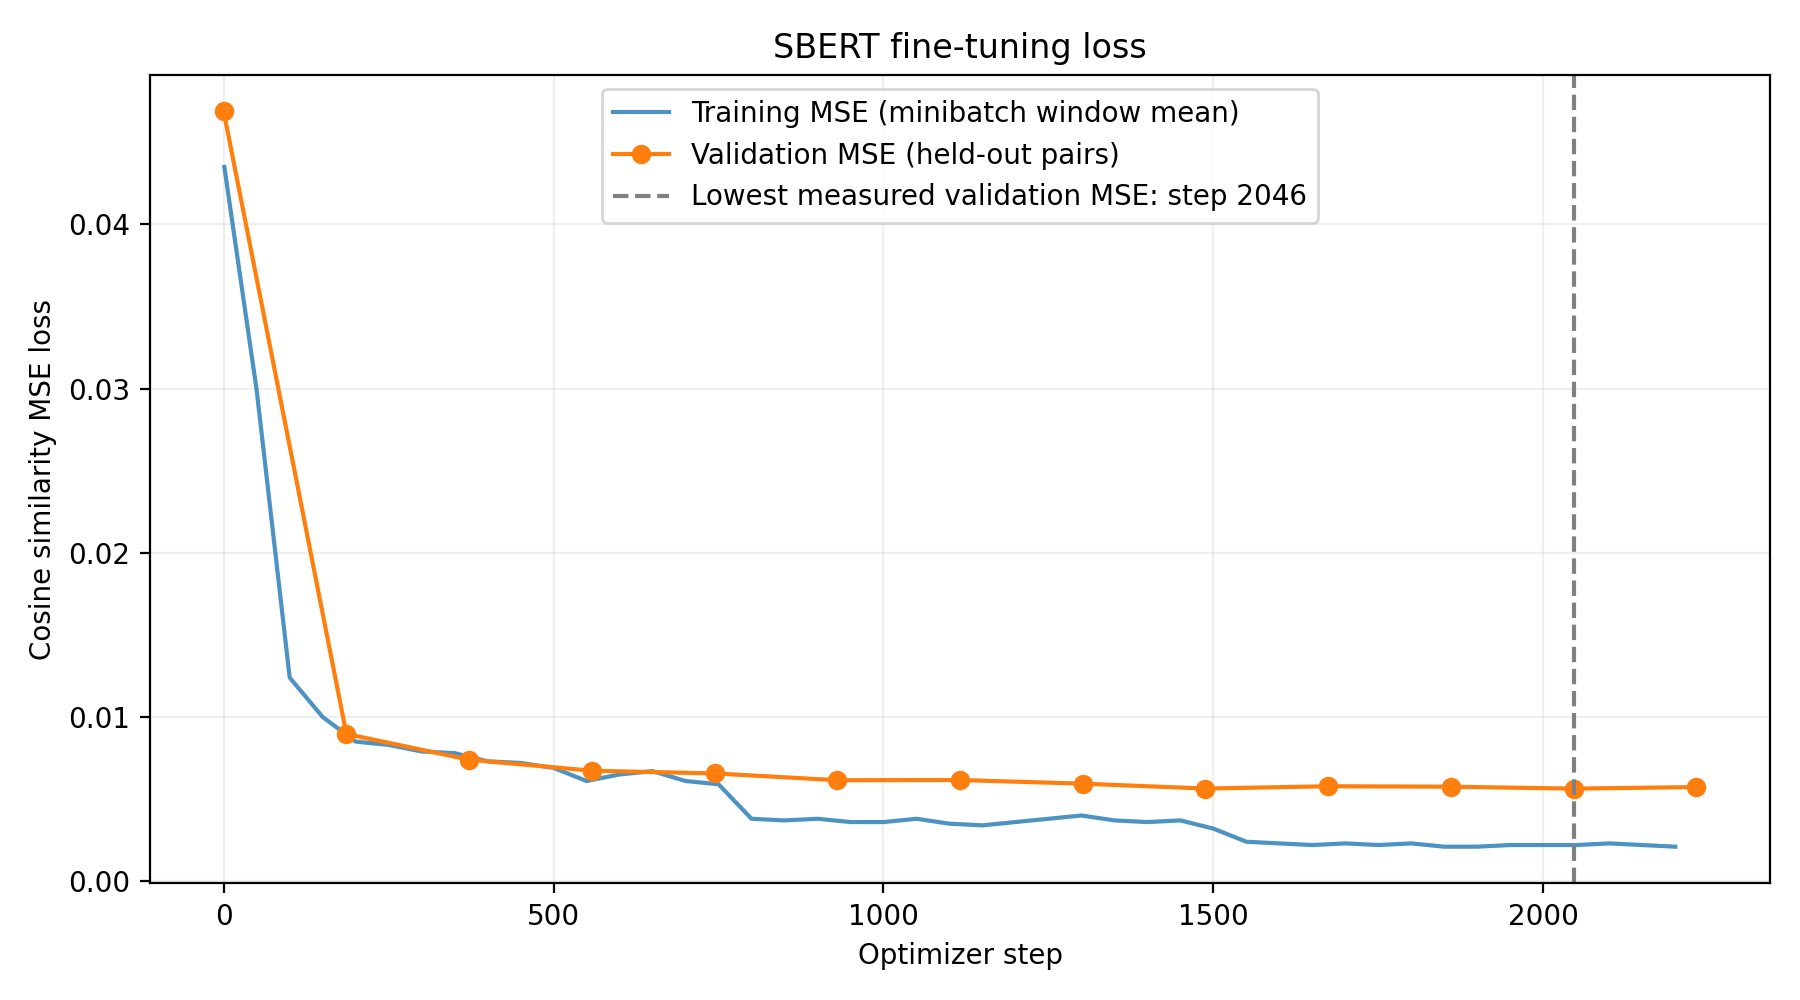

In [ ]:
finetuned_path = finetune_encoder(corpus, RUN_DIR, BASE_MODEL,
    epochs=FT_EPOCHS, batch_size=32, learning_rate=2e-5, weight_decay=0.01, seed=42)
print('Checkpoint mới:', finetuned_path)
from IPython.display import display, Image
display(Image(filename=str(RUN_DIR / 'figures/sbert_loss_curve.png')))


### Phân tích loss curve của SBERT

Trục ngang là số bước cập nhật trọng số; trục dọc là MSE giữa cosine embedding
và nhãn ROUGE-1 của cặp câu. Training loss được ghi ở bước đầu và tối đa mỗi 50 bước,
là trung bình loss minibatch từ lần ghi trước. Validation loss đo trên toàn bộ
các cặp validation, khoảng bốn lần mỗi epoch và có mốc ban đầu ở step 0.
Các chấm validation là điểm đo thật; đoạn nối chỉ giúp quan sát xu hướng.

- Cả hai loss giảm rồi chững: dấu hiệu hội tụ của hàm mục tiêu trên dữ liệu này.
- Train tiếp tục giảm nhưng validation tăng kéo dài: dấu hiệu có thể overfit;
  phân tích nhiều điểm liên tiếp, không kết luận từ một dao động đơn lẻ.
- Hai đường cùng cao và ít giảm: cần xem thêm learning rate, lượng dữ liệu,
  nhãn yếu và năng lực mô hình; chưa đủ bằng chứng để khẳng định một nguyên nhân.
- Train và validation không hoàn toàn cùng điều kiện đo: train có dropout và trọng số
  thay đổi trong cửa sổ ghi log; validation ở chế độ eval. Vì vậy validation thấp hơn
  train không tự động là lỗi. Loss này cũng khác cross-entropy của MLP.

Đường dọc đánh dấu validation loss thấp nhất sau khi bắt đầu train. Mốc step 0 giúp
kiểm tra fine-tuning có tốt hơn ban đầu trên hàm loss hay không; không tham gia chọn
checkpoint. Nếu mọi điểm sau train đều kém step 0, cần nêu rõ thay vì khẳng định cải thiện.
Loss giảm không bảo đảm ROUGE/BERTScore của bản tóm tắt tăng: phải đối chiếu bảng test.
Số liệu gốc lưu trong `finetune_loss_history.csv` và `.json`, hình trong
`figures/sbert_loss_curve.png`; tất cả có trong ZIP cuối notebook.


In [ ]:
# 7. Embedding của cùng các bài, hai encoder; không dùng API và không fallback mô hình.
pretrained_embeddings = cache_embeddings(corpus, RUN_DIR, BASE_MODEL, tag='pretrained')
finetuned_embeddings = cache_embeddings(corpus, RUN_DIR, finetuned_path, tag='finetuned')


Batches:   0%|          | 0/1563 [00:00<?, ?it/s]

Batches:   0%|          | 0/262 [00:00<?, ?it/s]

Batches:   0%|          | 0/524 [00:00<?, ?it/s]

Batches:   0%|          | 0/1563 [00:00<?, ?it/s]

Batches:   0%|          | 0/262 [00:00<?, ?it/s]

Batches:   0%|          | 0/524 [00:00<?, ?it/s]

## 8. Huấn luyện bộ chọn câu và lựa chọn mô hình

Nhãn câu oracle xấp xỉ được tạo bằng greedy tối đa ROUGE-1 + ROUGE-2 với ngân sách 3 câu.
Cả Logistic và MLP dùng embedding pretrained đóng băng, vị trí chuẩn hóa, log độ dài
và cosine với tâm bài. StandardScaler chỉ fit train. Không đưa reference vào đặc trưng.

Logistic: negative log-likelihood Bernoulli với L2, C ∈ {0,01; 1; 100}, solver L-BFGS.
MLP: một lớp ẩn 128 ReLU, cross-entropy với L2 alpha ∈ {0; 0,001; 0,1}, Adam/SGD,
cùng learning rate khởi tạo 0,001. SGD dùng momentum mặc định của sklearn;
đây là so sánh hai cấu hình optimizer tại learning rate cố định, không kết luận optimizer
nào tốt nhất với mọi learning rate. Không dùng dropout trong MLP sklearn này.

Early stopping MLP theo validation log-loss, patience 5, tối đa 40 epoch.
Chọn siêu tham số theo validation ROUGE-L, seed 42; sau đó lặp cấu hình thắng với
3 seed và 25%/50%/100% số bài train. Learning curve dùng các tập con lồng nhau.
Không dùng sentence-level random validation nội bộ. Các phép thử trên cùng validation
có thể gây thiên lệch lựa chọn; đây không phải nested cross-validation.


In [ ]:
selection = run_training(corpus, pretrained_embeddings, RUN_DIR,
    seeds=SEEDS, fractions=FRACTIONS, max_epochs=MAX_EPOCHS)
print('Cấu hình đã khóa:', {key: value['config'] for key, value in selection['winners'].items()})


{'family': 'logistic', 'C': 0.01} seed=42 train=3000: validation ROUGE-L=0.1934
{'family': 'logistic', 'C': 1.0} seed=42 train=3000: validation ROUGE-L=0.1932
{'family': 'logistic', 'C': 100.0} seed=42 train=3000: validation ROUGE-L=0.1932
{'family': 'mlp', 'alpha': 0.0, 'solver': 'adam'} seed=42 train=3000: validation ROUGE-L=0.1893
{'family': 'mlp', 'alpha': 0.001, 'solver': 'adam'} seed=42 train=3000: validation ROUGE-L=0.1883
{'family': 'mlp', 'alpha': 0.1, 'solver': 'adam'} seed=42 train=3000: validation ROUGE-L=0.1917
{'family': 'mlp', 'alpha': 0.0, 'solver': 'sgd'} seed=42 train=3000: validation ROUGE-L=0.1900
{'family': 'mlp', 'alpha': 0.001, 'solver': 'sgd'} seed=42 train=3000: validation ROUGE-L=0.1902
{'family': 'mlp', 'alpha': 0.1, 'solver': 'sgd'} seed=42 train=3000: validation ROUGE-L=0.1901
{'family': 'logistic', 'C': 0.01} seed=42 train=750: validation ROUGE-L=0.1877
{'family': 'logistic', 'C': 0.01} seed=42 train=1500: validation ROUGE-L=0.1939
{'family': 'logistic', '

## 9. Đánh giá test sau khi khóa lựa chọn

Tất cả phương pháp chọn đúng 3 câu từ cùng tập câu ứng viên và khôi phục thứ tự gốc.
Lead-3, TF-IDF TextRank, centroid, K-Means thuần, Logistic, MLP. So sánh pretrained
với fine-tuned dùng cùng centroid/K-Means: không gộp thay đổi encoder với thay đổi bộ chọn câu.
K-Means thuần là ablation có kiểm soát, chưa bao gồm adaptive K/position weighting/
lọc trùng của sản phẩm cũ. Các mô hình đều không dùng post-filter trong bảng chính.

ROUGE tiếng Việt dùng token âm tiết Unicode có dấu; tiếng Anh dùng stemming mặc định.
ROUGE-L ở đây là LCS toàn văn bản, không phải ROUGE-Lsum.
Ngân sách theo câu chưa bảo đảm bằng nhau về số từ; bảng lưu thêm độ dài và tỷ lệ giữ từ.

Xuất điểm từng bài, trung bình từng seed và độ lệch chuẩn giữa seed.
Paired bootstrap 2.000 lần theo bài báo cho chênh lệch ROUGE-L với pretrained K-Means,
sau khi trung bình các seed của từng bài. CI 95% chưa hiệu chỉnh nhiều so sánh,
mang tính khám phá; CI này không đồng thời đo bất định do chọn siêu tham số/fine-tuning.
Thời gian selector tách khỏi thời gian embedding; không gọi đó là độ trễ end-to-end.


In [ ]:
test_rows = run_test(corpus, pretrained_embeddings, selection, RUN_DIR,
                     finetuned_embeddings=finetuned_embeddings)


Đã đánh giá pretrained_lead, seed=42
Đã đánh giá pretrained_textrank, seed=42
Đã đánh giá pretrained_centroid, seed=42
Đã đánh giá pretrained_kmeans, seed=42
Đã đánh giá pretrained_kmeans, seed=123
Đã đánh giá pretrained_kmeans, seed=2026
Đã đánh giá finetuned_centroid, seed=42
Đã đánh giá finetuned_kmeans, seed=42
Đã đánh giá finetuned_kmeans, seed=123
Đã đánh giá finetuned_kmeans, seed=2026
Đã đánh giá logistic, seed=42
Đã đánh giá logistic, seed=123
Đã đánh giá logistic, seed=2026
Đã đánh giá mlp, seed=42
Đã đánh giá mlp, seed=123
Đã đánh giá mlp, seed=2026
finetuned_centroid: ROUGE-L=0.1762, seed std=None
finetuned_kmeans: ROUGE-L=0.1779, seed std=0.0008331428121897468
logistic: ROUGE-L=0.1913, seed std=3.3993498887762956e-17
mlp: ROUGE-L=0.1870, seed std=0.0012800428199916478
pretrained_centroid: ROUGE-L=0.1773, seed std=None
pretrained_kmeans: ROUGE-L=0.1766, seed std=0.0017108395407959946
pretrained_lead: ROUGE-L=0.1888, seed std=None
pretrained_textrank: ROUGE-L=0.1756, seed st

In [ ]:
# 10. BERTScore độc lập: có thể chạy lại nếu Colab ngắt, đã có cache theo bản tóm tắt.
# Không trả 0 khi lỗi tải model. Cell lỗi phải xử lý rồi mới dùng bảng có BERTScore.
add_bertscore(corpus, RUN_DIR, batch_size=16)


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

BERTScore: 16/10306 bản tóm tắt còn thiếu
BERTScore: 416/10306 bản tóm tắt còn thiếu
BERTScore: 816/10306 bản tóm tắt còn thiếu
BERTScore: 1216/10306 bản tóm tắt còn thiếu
BERTScore: 1616/10306 bản tóm tắt còn thiếu
BERTScore: 2016/10306 bản tóm tắt còn thiếu
BERTScore: 2416/10306 bản tóm tắt còn thiếu
BERTScore: 2816/10306 bản tóm tắt còn thiếu
BERTScore: 3216/10306 bản tóm tắt còn thiếu
BERTScore: 3616/10306 bản tóm tắt còn thiếu
BERTScore: 4016/10306 bản tóm tắt còn thiếu
BERTScore: 4416/10306 bản tóm tắt còn thiếu
BERTScore: 4816/10306 bản tóm tắt còn thiếu
BERTScore: 5216/10306 bản tóm tắt còn thiếu
BERTScore: 5616/10306 bản tóm tắt còn thiếu
BERTScore: 6016/10306 bản tóm tắt còn thiếu
BERTScore: 6416/10306 bản tóm tắt còn thiếu
BERTScore: 6816/10306 bản tóm tắt còn thiếu
BERTScore: 7216/10306 bản tóm tắt còn thiếu
BERTScore: 7616/10306 bản tóm tắt còn thiếu
BERTScore: 8016/10306 bản tóm tắt còn thiếu
BERTScore: 8416/10306 bản tóm tắt còn thiếu
BERTScore: 8816/10306 bản tóm tắt cò

,model,runs,rouge1_mean,rouge1_seed_std,rouge2_mean,rouge2_seed_std,rougeL_mean,rougeL_seed_std,words_mean,words_seed_std,word_retention_mean,word_retention_seed_std,bertscore_f1_mean,bertscore_f1_seed_std
0,finetuned_centroid,1,0.240626,NaN,0.123030,NaN,0.176233,NaN,87.303,NaN,0.243092,NaN,0.717475,NaN
1,finetuned_kmeans,3,0.260589,0.001571,0.127507,0.001303,0.177892,8.331428e-04,77.534,0.060108,0.223393,0.000226,0.727517,0.000652
2,logistic,3,0.259526,0.000000,0.132944,0.000000,0.191300,3.399350e-17,48.916,0.000000,0.148636,0.000000,0.722737,0.000000
3,mlp,3,0.258754,0.001710,0.129663,0.001238,0.186970,1.280043e-03,53.335,1.387093,0.161114,0.003905,0.723317,0.000221
4,pretrained_centroid,1,0.246261,NaN,0.126129,NaN,0.177301,NaN,90.349,NaN,0.254041,NaN,0.723560,NaN
5,pretrained_kmeans,3,0.259815,0.002791,0.126603,0.002155,0.176644,1.710840e-03,77.678,0.182096,0.222335,0.000597,0.727344,0.001012
6,pretrained_lead,1,0.267662,NaN,0.143240,NaN,0.188761,NaN,85.456,NaN,0.250707,NaN,0.731561,NaN
7,pretrained_textrank,1,0.239856,NaN,0.121953,NaN,0.175576,NaN,91.512,NaN,0.251604,NaN,0.715697,NaN


,model,baseline,metric,delta,ci_low,ci_high
0,finetuned_centroid,pretrained_kmeans,rougeL,-0.000412,-0.005436,0.004442
1,finetuned_kmeans,pretrained_kmeans,rougeL,0.001248,-0.002704,0.005028
2,logistic,pretrained_kmeans,rougeL,0.014655,0.008589,0.020668
3,mlp,pretrained_kmeans,rougeL,0.010326,0.005353,0.015332
4,pretrained_centroid,pretrained_kmeans,rougeL,0.000657,-0.003696,0.005140
5,pretrained_lead,pretrained_kmeans,rougeL,0.012117,0.006842,0.017388
6,pretrained_textrank,pretrained_kmeans,rougeL,-0.001068,-0.006004,0.003679


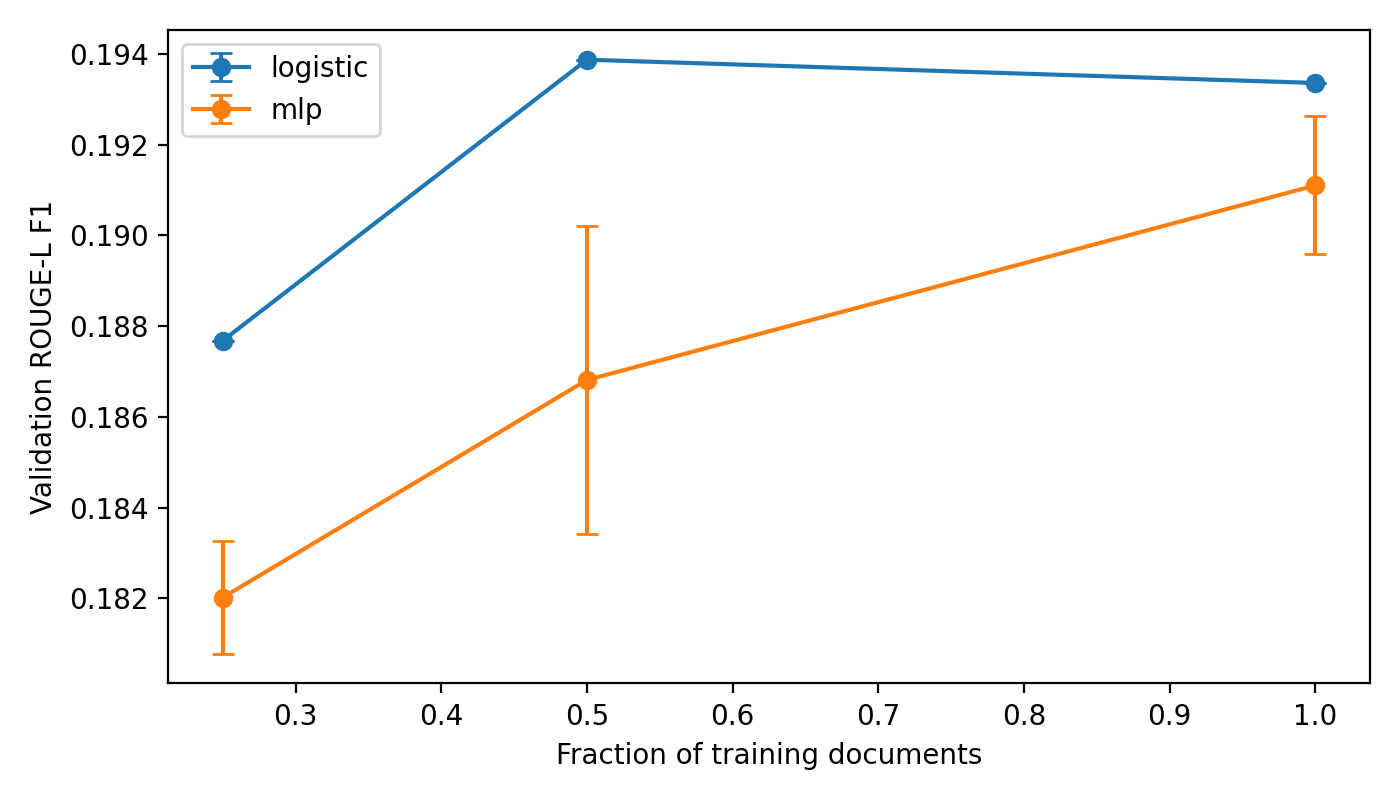

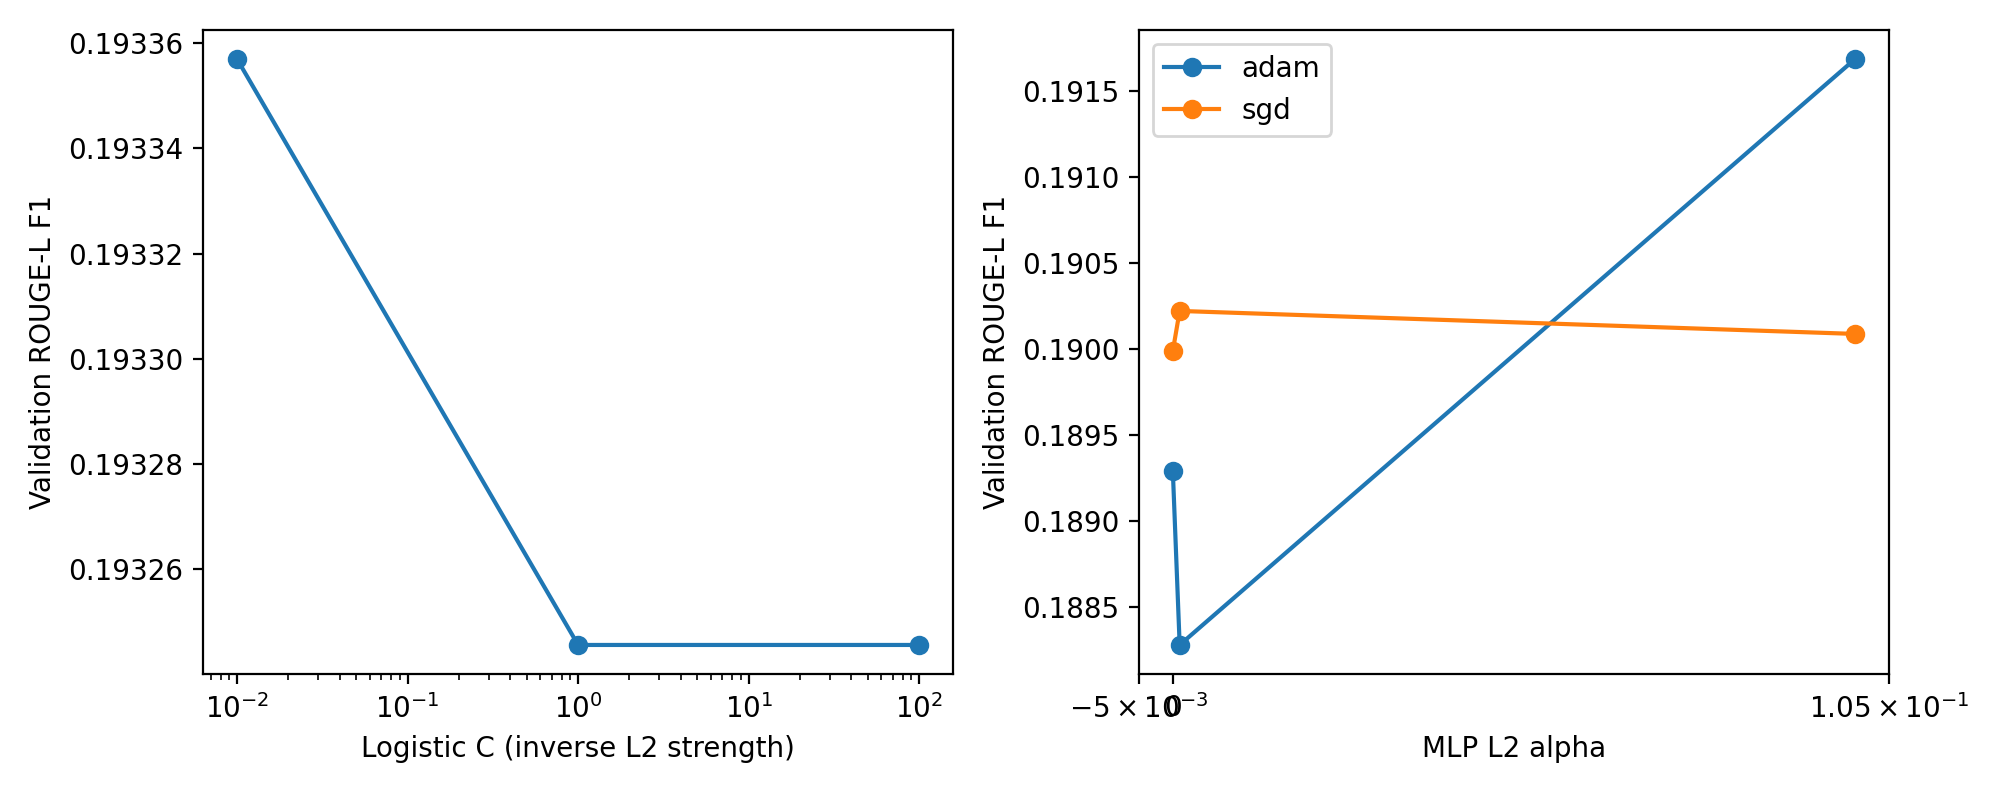

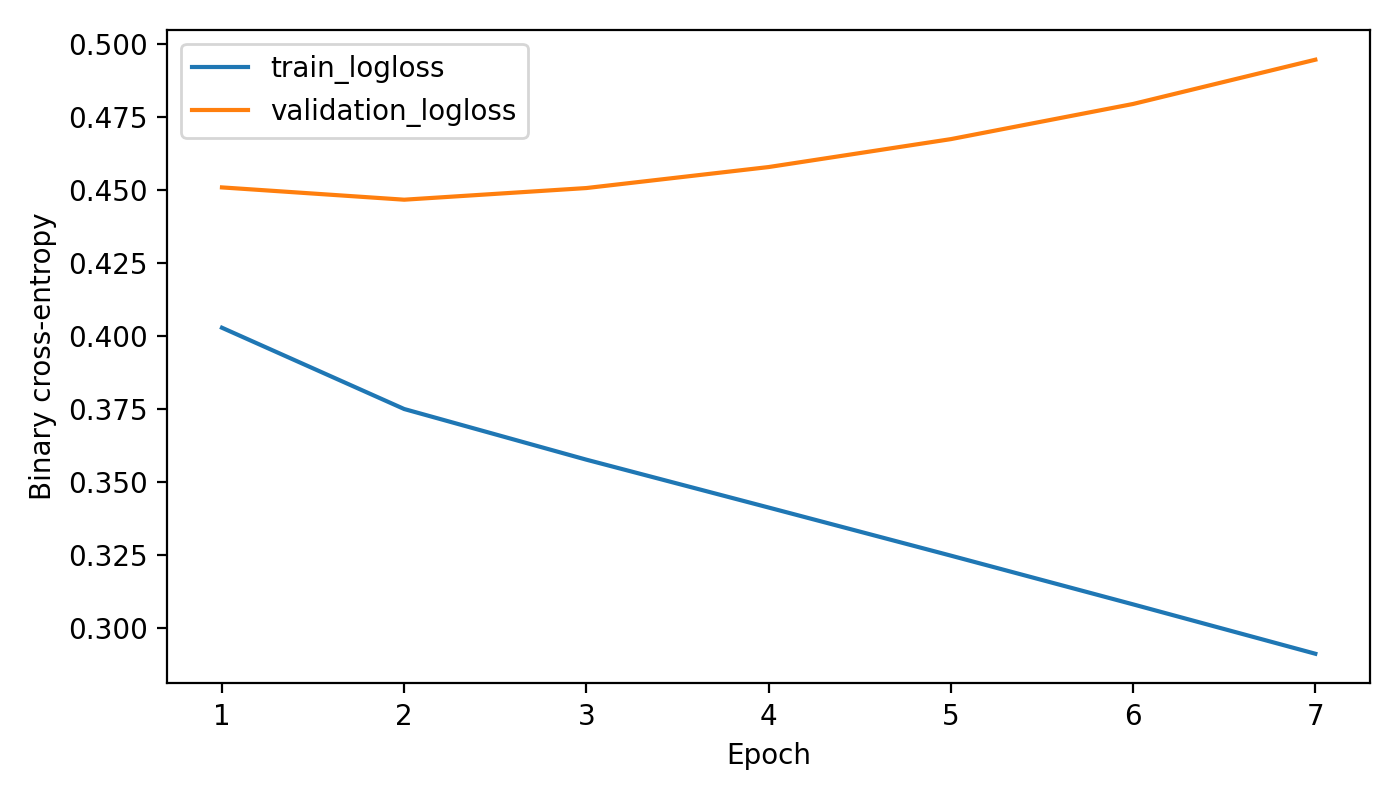

In [ ]:
# 11. Xuất hình và xem bảng cuối.
make_plots(RUN_DIR)
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv(RUN_DIR / 'test_summary.csv'))
display(pd.read_csv(RUN_DIR / 'paired_bootstrap.csv'))
display(Image(filename=str(RUN_DIR / 'figures/learning_curve.png')))
display(Image(filename=str(RUN_DIR / 'figures/regularization_optimizer.png')))
display(Image(filename=str(RUN_DIR / 'figures/mlp_convergence.png')))


## 12. Đóng gói toàn bộ kết quả và tải về máy

Cell cuối nén toàn bộ thư mục kết quả, gồm bảng CSV, hình, cấu hình, dữ liệu,
embedding và mô hình đã huấn luyện, thành một file ZIP rồi tải về máy.
Lưu thêm notebook có output và gửi lại cùng file ZIP để cập nhật báo cáo.
Tải xong trước khi kết thúc phiên Colab vì file chưa tải về có thể mất khi phiên bị xóa.


In [ ]:
from datetime import datetime, timezone
import shutil

save_json(RUN_DIR / 'execution_status.json', dict(
    finished_utc=datetime.now(timezone.utc).isoformat(),
    ready_for_report=(RUN_DIR / 'bertscore_metadata.json').exists()))
result_zip = shutil.make_archive(
    str(RUN_DIR.parent / f'{RUN_DIR.name}_results'), 'zip', root_dir=str(RUN_DIR))
print('Đã đóng gói toàn bộ kết quả:', result_zip)
print(f'Dung lượng: {Path(result_zip).stat().st_size / (1024 ** 2):.1f} MB')
if IN_COLAB:
    from google.colab import files
    files.download(result_zip)


Đã đóng gói toàn bộ kết quả: /content/Extractive-Summarizer/outputs/advanced_ml/advanced_ml_v2_vi_results.zip
Dung lượng: 2152.0 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Ablation đặc trưng — chạy riêng trên runtime mới
Tám cấu hình: chỉ embedding; embedding + lần lượt vị trí/độ dài/tâm bài;
đầy đủ; đầy đủ bỏ lần lượt vị trí/độ dài/tâm bài. Cùng dữ liệu, ngân sách ba câu,
cấu hình Logistic C=0,01, MLP Adam alpha=0,1, 128 ReLU và ba seed 42/123/2026.
Giữ nguyên siêu tham số để đo ảnh hưởng của đặc trưng, không tìm lại theo test.
Chỉ các head có đầu vào khác mới cần train lại; không huấn luyện encoder.

Đánh giá ROUGE-1/2/L, độ dài và paired bootstrap ROUGE-L theo bài (trung bình seed).
Không chạy lại BERTScore để tiết kiệm thời gian. Bảng ablation vì vậy chỉ so sánh
các chỉ số được đo ở đây. Hai cách thêm/bỏ đặc trưng đo ảnh hưởng có điều kiện,
không phải phép phân bổ đóng góp độc lập khi các đặc trưng tương tác.


In [1]:
# 13.1. Thiết lập độc lập: clone mã và cài đúng các phiên bản tạo đặc trưng/head.
import os
import sys
import subprocess
from pathlib import Path

ABL_IN_COLAB = 'google.colab' in sys.modules
if ABL_IN_COLAB:
    abl_repo = Path('/content/Extractive-Summarizer')
    if not (abl_repo / '.git').exists():
        subprocess.run(['git', 'clone', '--depth', '1',
                        'https://github.com/kttt294/Extractive-Summarizer.git', str(abl_repo)], check=True)
    os.chdir(abl_repo)
assert Path('src/advanced_ml.py').is_file(), 'Mở notebook từ thư mục dự án.'
sys.path.insert(0, str(Path.cwd()))
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
    'numpy==2.1.3', 'scikit-learn==1.6.1', 'underthesea==8.3.0',
    'sentence-transformers==3.4.1', 'transformers==4.57.6',
    'huggingface-hub>=0.34,<1', 'datasets>=2.19,<4', 'rouge-score==0.1.2',
    'pandas>=2,<3', 'matplotlib>=3.8,<4', 'joblib>=1.3,<2'], check=True)
import importlib.metadata
import numpy as np
import sklearn
if np.__version__ != '2.1.3' or sklearn.__version__ != '1.6.1':
    raise RuntimeError('Khởi động lại runtime rồi chạy lại riêng mục 13 để nạp phiên bản vừa cài.')
import torch
print('Thiết bị:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU; nên chọn GPU T4')


Thiết bị: Tesla T4


In [2]:
# 13.2. Tải head/scaler và metadata từ Hugging Face, không upload weights thủ công.
import json
import hashlib
import joblib
from huggingface_hub import hf_hub_download
from src.advanced_ml import save_json, record_environment

ABL_DIR = Path('outputs/advanced_ml/feature_ablation_vi').resolve()
ABL_DIR.mkdir(parents=True, exist_ok=True)
ABL_SEEDS = (42, 123, 2026)
ABL_HEAD_REPO = 'kttt294/vietnamese-extractive-heads-advanced-ml-v2'
ABL_HEAD_REVISION = 'cd69d02069d708c2fd8a6b4a78089ff5d1b930b6'
def abl_hub_file(name):
    return hf_hub_download(ABL_HEAD_REPO, filename=name,
                           revision=ABL_HEAD_REVISION, token=False)

abl_selection = json.loads(Path(abl_hub_file('selection.json')).read_text(encoding='utf-8'))
abl_deployment = json.loads(Path(abl_hub_file('deployment_manifest.json')).read_text(encoding='utf-8'))
abl_original_environment = json.loads(Path(abl_hub_file('environment.json')).read_text(encoding='utf-8'))
# Dùng đúng phiên bản datasets đã lấy mẫu/shuffle ở lượt cũ.
original_datasets_version = abl_original_environment['packages']['datasets']
if importlib.metadata.version('datasets') != original_datasets_version:
    if 'datasets' in sys.modules:
        raise RuntimeError('Khởi động lại runtime và chạy riêng mục 13 để khớp datasets của lượt gốc.')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'datasets==' + original_datasets_version], check=True)
abl_original_summary = Path(abl_hub_file('test_summary.csv')).read_text(encoding='utf-8-sig')
(ABL_DIR/'original_test_summary.csv').write_text(abl_original_summary, encoding='utf-8')
abl_full_heads = {}
for family in ('logistic', 'mlp'):
    for seed in ABL_SEEDS:
        name = f'{family}_seed{seed}.joblib'
        path = Path(abl_hub_file('heads/' + name))
        if hashlib.sha256(path.read_bytes()).hexdigest() != abl_deployment['head_files'][name]:
            raise RuntimeError(f'Checksum không khớp: {name}')
        fitted = joblib.load(path)  # Chỉ nạp artifact từ repository của nhóm đã xác minh checksum.
        if fitted['params'] != abl_selection['winners'][family]['config'] or fitted['seed'] != seed:
            raise RuntimeError(f'Sai cấu hình head: {name}')
        abl_full_heads[(family, seed)] = fitted
save_json(ABL_DIR/'original_selection.json', abl_selection)
save_json(ABL_DIR/'original_environment.json', abl_original_environment)
save_json(ABL_DIR/'model_source.json', dict(repo=ABL_HEAD_REPO, revision=ABL_HEAD_REVISION,
          checksums=abl_deployment['head_files'], encoder=abl_selection['settings']['encoder']))
record_environment(ABL_DIR)
print('Đã tải sáu head; không cần tải encoder fine-tuned hoặc fine-tune lại.')


selection.json: 0.00B [00:00, ?B/s]

deployment_manifest.json: 0.00B [00:00, ?B/s]

environment.json: 0.00B [00:00, ?B/s]

test_summary.csv: 0.00B [00:00, ?B/s]

heads/logistic_seed42.joblib:   0%|          | 0.00/26.1k [00:00<?, ?B/s]

...

heads/logistic_seed2026.joblib:   0%|          | 0.00/26.1k [00:00<?, ?B/s]

heads/mlp_seed42.joblib:   0%|          | 0.00/1.61M [00:00<?, ?B/s]

heads/mlp_seed123.joblib:   0%|          | 0.00/1.61M [00:00<?, ?B/s]

heads/mlp_seed2026.joblib:   0%|          | 0.00/1.61M [00:00<?, ?B/s]

Đã tải sáu head; không cần tải encoder fine-tuned hoặc fine-tune lại.


In [3]:
# 13.3. Tái tạo đúng mẫu dữ liệu cũ và embedding pretrained, kiểm tra digest.
from src.advanced_ml import prepare_corpus, digest, encoder_text
from sentence_transformers import SentenceTransformer

if ('corpus' in globals()
        and corpus.get('digest') == abl_selection['settings']['corpus']):
    abl_corpus = corpus
else:
    abl_corpus = prepare_corpus(ABL_DIR, 'nam194/vietnews', 'vi',
        counts={'train': 3000, 'validation': 500, 'test': 1000}, seed=42, k=3)
if abl_corpus['digest'] != abl_selection['settings']['corpus']:
    raise RuntimeError('Mẫu dữ liệu khác lượt gốc; dừng để tránh so sánh sai với head đã tải.')
save_json(ABL_DIR/'corpus_identity.json', dict(digest=abl_corpus['digest'],
          revision=abl_corpus['resolved_revision'], audit=abl_corpus['audit']))
abl_encoder_identity = abl_selection['settings']['encoder']
abl_embeddings = None
if 'pretrained_embeddings' in globals() and 'RUN_DIR' in globals():
    old_manifest = Path(RUN_DIR)/'embeddings/pretrained/manifest.json'
    if old_manifest.exists() and json.loads(old_manifest.read_text()) == abl_encoder_identity:
        abl_embeddings = pretrained_embeddings
        print('Dùng lại embedding pretrained đúng revision trong phiên hiện tại.')
if abl_embeddings is None:
    abl_embeddings = {}
    abl_encoder = None
    emb_dir = ABL_DIR/'embeddings'
    emb_dir.mkdir(exist_ok=True)
    identity_path = emb_dir/'identity.json'
    if identity_path.exists() and json.loads(identity_path.read_text()) != abl_encoder_identity:
        raise RuntimeError('Cache embedding khác nguồn model. Dùng thư mục ablation mới.')
    save_json(identity_path, abl_encoder_identity)
    for split, docs in abl_corpus['splits'].items():
        cache_path = emb_dir/f'{split}.npz'
        if cache_path.exists():
            with np.load(cache_path, allow_pickle=False) as cached:
                arrays = [cached[f'd{i}'] for i in range(len(docs))]
        else:
            if abl_encoder is None:
                abl_encoder = SentenceTransformer(abl_encoder_identity['model'],
                    revision=abl_encoder_identity['revision'],
                    device='cuda' if torch.cuda.is_available() else 'cpu')
                if abl_encoder.max_seq_length != 256:
                    raise RuntimeError('max_seq_length khác cấu hình pretrained gốc.')
            texts = [encoder_text(s, 'vi') for d in docs for s in d['sentences']]
            encoded = abl_encoder.encode(texts, batch_size=32, convert_to_numpy=True,
                normalize_embeddings=True, show_progress_bar=True)
            arrays, offset = [], 0
            for doc in docs:
                size = len(doc['sentences'])
                arrays.append(encoded[offset:offset+size].astype(np.float32))
                offset += size
            np.savez_compressed(cache_path, **{f'd{i}': a for i, a in enumerate(arrays)})
        if (len(arrays) != len(docs) or any(a.shape != (len(d['sentences']), 768)
                or not np.isfinite(a).all() for a, d in zip(arrays, docs))):
            raise RuntimeError(f'Embedding không hợp lệ: {split}')
        abl_embeddings[split] = arrays
    del abl_encoder
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
print('Dữ liệu khớp lượt gốc:', abl_corpus['digest'])


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/748 [00:00<?, ?B/s]

data/train-00000-of-00001-84acb79f6c6547(…):   0%|          | 0.00/170M [00:00<?, ?B/s]

data/validation-00000-of-00001-210cc51bf(…):   0%|          | 0.00/38.3M [00:00<?, ?B/s]

data/test-00000-of-00001-123f98d55067eb7(…):   0%|          | 0.00/38.8M [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/270 [00:00<?, ?B/s]

Batches:   0%|          | 0/1563 [00:00<?, ?it/s]

Batches:   0%|          | 0/262 [00:00<?, ?it/s]

Batches:   0%|          | 0/524 [00:00<?, ?it/s]

Dữ liệu khớp lượt gốc: e572031a2363881e8528018d3adf256e9416795caa428459e53340f74242ffac


In [4]:
# 13.4. Cắt đúng cột đầu vào; fit scaler riêng cho mỗi cấu hình, chỉ trên train.
from src.advanced_ml import (features, labels, fit_head, select_top, score_rows,
                             write_csv, paired_bootstrap)


def ablation_columns(embedding_dim):
    embedding = list(range(embedding_dim))
    position, length, centroid = range(embedding_dim, embedding_dim+3)
    return {
        'embedding_only': embedding,
        'embedding_position': embedding + [position],
        'embedding_length': embedding + [length],
        'embedding_centroid': embedding + [centroid],
        'full': embedding + [position, length, centroid],
        'without_position': embedding + [length, centroid],
        'without_length': embedding + [position, centroid],
        'without_centroid': embedding + [position, length],
    }


def run_feature_ablation(corpus, embeddings, selection, full_heads, root,
                         seeds=(42, 123, 2026), max_epochs=40):
    from src.metrics import make_rouge_scorer
    root = Path(root)
    scorer = make_rouge_scorer('vi')
    docs = corpus['splits']
    columns = ablation_columns(embeddings['train'][0].shape[1])
    params = {f: selection['winners'][f]['config'] for f in ('logistic', 'mlp')}
    protocol = dict(corpus=corpus['digest'], columns=columns, params=params,
                    seeds=list(seeds), max_epochs=max_epochs, k=3,
                    feature_order=['embedding', 'relative_position', 'log1p_length', 'centroid_cosine'],
                    selection='fixed original hyperparameters; validation log-loss early stopping only')
    lock_path = root/'ablation_protocol.json'
    if lock_path.exists() and json.loads(lock_path.read_text()) != protocol:
        raise ValueError('Thiết kế ablation đã đổi; dùng thư mục mới.')
    save_json(lock_path, protocol)
    # Không tạo nhãn từ test. Cache nhãn để không lặp greedy ROUGE khi chạy lại.
    target = {}
    for split in ('train', 'validation'):
        path = root/f'{split}_oracle_labels.npz'
        if path.exists():
            with np.load(path, allow_pickle=False) as data:
                yy = [data[f'd{i}'] for i in range(len(docs[split]))]
        else:
            print('Tạo nhãn oracle:', split, flush=True)
            yy = labels(docs[split], scorer, 3)
            np.savez_compressed(path, **{f'd{i}': y for i, y in enumerate(yy)})
        target[split] = np.concatenate(yy)
    matrices = {s: [features(d, e) for d, e in zip(docs[s], embeddings[s])]
                for s in ('train', 'validation', 'test')}
    train_x, val_x = np.vstack(matrices['train']), np.vstack(matrices['validation'])
    all_rows, fit_rows = [], []
    (root/'heads').mkdir(exist_ok=True)
    for family in ('logistic', 'mlp'):
        for variant, cols in columns.items():
            for seed in seeds:
                key = f'{family}_{variant}_seed{seed}'
                artifact = root/'heads'/f'{key}.joblib'
                if variant == 'full':
                    fitted = full_heads[(family, seed)]
                    origin = 'downloaded_original_head'
                elif artifact.exists():
                    fitted = joblib.load(artifact)
                    origin = 'cached_ablation_head'
                else:
                    fitted = fit_head(train_x[:, cols], target['train'], val_x[:, cols],
                        target['validation'], params[family], seed, max_epochs=max_epochs)
                    joblib.dump(fitted, artifact)
                    origin = 'new_ablation_head'
                if fitted['scaler'].n_features_in_ != len(cols):
                    raise ValueError(f'Sai số chiều của {key}')
                write_csv(root/'traces'/f'{key}.csv', fitted['trace'])
                fit_rows.append(dict(family=family, variant=variant, seed=seed,
                    features=len(cols), parameters=fitted['parameters'], origin=origin,
                    original_fit_seconds=fitted['train_seconds']))
                for split in ('validation', 'test'):
                    predictions = [select_top(fitted['model'].predict_proba(
                        fitted['scaler'].transform(x[:, cols]))[:, 1], 3) for x in matrices[split]]
                    rows = score_rows(docs[split], predictions, scorer, family, seed)
                    for row in rows:
                        row.update(family=family, variant=variant, split=split)
                    all_rows.extend(rows)
                print(f'{key}: hoàn tất', flush=True)
            write_csv(root/'ablation_per_document.csv', all_rows)
            write_csv(root/'ablation_fits.csv', fit_rows)
    return all_rows

abl_rows = run_feature_ablation(abl_corpus, abl_embeddings, abl_selection,
                                abl_full_heads, ABL_DIR, ABL_SEEDS)


Tạo nhãn oracle: train
Tạo nhãn oracle: validation
logistic_embedding_only_seed42: hoàn tất
logistic_embedding_only_seed123: hoàn tất
logistic_embedding_only_seed2026: hoàn tất
logistic_embedding_position_seed42: hoàn tất
logistic_embedding_position_seed123: hoàn tất
logistic_embedding_position_seed2026: hoàn tất
logistic_embedding_length_seed42: hoàn tất
logistic_embedding_length_seed123: hoàn tất
logistic_embedding_length_seed2026: hoàn tất
logistic_embedding_centroid_seed42: hoàn tất
logistic_embedding_centroid_seed123: hoàn tất
logistic_embedding_centroid_seed2026: hoàn tất
logistic_full_seed42: hoàn tất
logistic_full_seed123: hoàn tất
logistic_full_seed2026: hoàn tất
logistic_without_position_seed42: hoàn tất
logistic_without_position_seed123: hoàn tất
logistic_without_position_seed2026: hoàn tất
logistic_without_length_seed42: hoàn tất
logistic_without_length_seed123: hoàn tất
logistic_without_length_seed2026: hoàn tất
logistic_without_centroid_seed42: hoàn tất
logistic_without_c

Kiểm tra FULL tải từ Hub so với kết quả cũ (chưa quy kết nguyên nhân nếu có chênh lệch):


,family,original_rougeL,reproduced_rougeL,delta_points
0,logistic,0.19130,0.19130,0.0
1,mlp,0.18697,0.18697,0.0


Test: ROUGE theo thang 0–100; std là biến thiên giữa ba seed.


,family,variant,rouge1_mean,rouge2_mean,rougeL_mean,rougeL_std,words_mean
0,logistic,embedding_centroid,24.8726,12.5735,18.3018,0.0000,54.7960
1,logistic,embedding_length,24.4878,11.8536,17.8379,0.0000,44.4790
2,logistic,embedding_only,24.6253,12.2934,17.9405,0.0000,53.0060
3,logistic,embedding_position,25.2674,12.8586,18.2790,0.0000,57.7410
4,logistic,full,25.9526,13.2944,19.1300,0.0000,48.9160
5,logistic,without_centroid,25.7375,13.0090,18.5154,0.0000,47.8790
6,logistic,without_length,25.7135,13.2546,18.6958,0.0000,59.1700
7,logistic,without_position,25.0387,12.4478,18.4873,0.0000,45.5430
8,mlp,embedding_centroid,25.2305,12.6128,18.1877,0.3514,59.1983
9,mlp,embedding_length,24.5552,11.9661,17.7059,0.2384,49.9687


Chênh lệch = cột left − cột right; CI theo bài, chưa hiệu chỉnh nhiều so sánh.


,family,left,right,contrast,delta_RL_points,ci_low_points,ci_high_points
0,logistic,full,embedding_only,full_minus_embedding_only,1.1895,0.7171,1.6997
1,logistic,full,embedding_position,full_minus_embedding_position,0.8509,0.4354,1.2554
2,logistic,full,embedding_length,full_minus_embedding_length,1.2921,0.8432,1.7608
3,logistic,full,embedding_centroid,full_minus_embedding_centroid,0.8282,0.3783,1.2934
4,logistic,full,without_position,full_minus_without_position,0.6427,0.2431,1.0539
5,logistic,full,without_length,full_minus_without_length,0.4342,0.0210,0.8530
6,logistic,full,without_centroid,full_minus_without_centroid,0.6145,0.2533,0.9604
7,logistic,embedding_position,embedding_only,embedding_position_minus_embedding_only,0.3385,-0.0987,0.7604
8,logistic,embedding_length,embedding_only,embedding_length_minus_embedding_only,-0.1026,-0.5195,0.2876
9,logistic,embedding_centroid,embedding_only,embedding_centroid_minus_embedding_only,0.3613,0.0203,0.7125


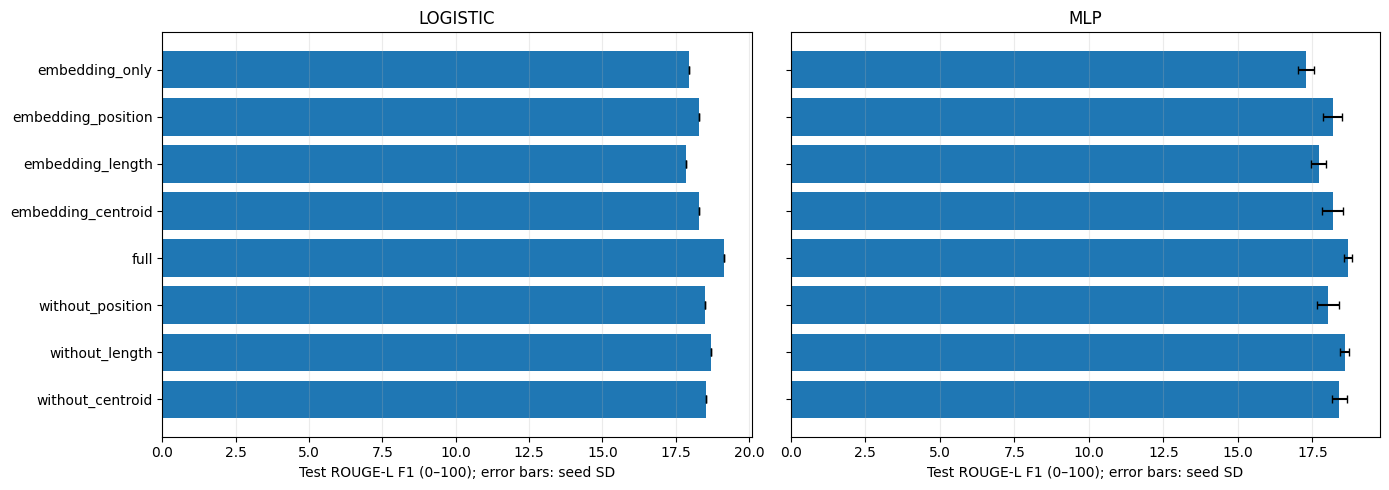

Đọc full − without_position/length/centroid để đo tác dụng khi đã có các đặc trưng còn lại.
Đọc embedding_position/length/centroid so với embedding_only để đo tác dụng khi thêm riêng lẻ.
CI chứa 0: chưa có bằng chứng rõ về chênh lệch trong phép đo này; không đồng nghĩa hai cách tương đương.


In [5]:
# 13.5. Bảng trung bình ± SD seed và CI paired bootstrap theo bài.
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

abl_frame = pd.DataFrame(abl_rows)
abl_metrics = ['rouge1', 'rouge2', 'rougeL', 'words', 'word_retention']
abl_seed_means = abl_frame.groupby(['split', 'family', 'variant', 'seed'])[abl_metrics].mean().reset_index()
abl_seed_means.to_csv(ABL_DIR/'ablation_per_seed.csv', index=False)
abl_summary = abl_seed_means.groupby(['split', 'family', 'variant'])[abl_metrics].agg(['mean', 'std'])
abl_summary.columns = ['_'.join(c) for c in abl_summary.columns]
abl_summary = abl_summary.reset_index()
abl_summary.to_csv(ABL_DIR/'ablation_summary.csv', index=False)
abl_original_means = pd.read_csv(ABL_DIR/'original_test_summary.csv').set_index('model')
abl_full_means = abl_summary[(abl_summary.split == 'test') & (abl_summary.variant == 'full')].set_index('family')
abl_reproduction = []
for family in ('logistic', 'mlp'):
    old = float(abl_original_means.loc[family, 'rougeL_mean'])
    current = float(abl_full_means.loc[family, 'rougeL_mean'])
    abl_reproduction.append(dict(family=family, original_rougeL=old, reproduced_rougeL=current,
                                delta_points=100*(current-old)))
abl_reproduction = pd.DataFrame(abl_reproduction)
abl_reproduction.to_csv(ABL_DIR/'baseline_reproduction.csv', index=False)
print('Kiểm tra FULL tải từ Hub so với kết quả cũ (chưa quy kết nguyên nhân nếu có chênh lệch):')
display(abl_reproduction.round(6))
abl_order = list(ablation_columns(768))
abl_test = abl_frame[abl_frame['split'] == 'test']
abl_pairs = []
for family in ('logistic', 'mlp'):
    per_doc = abl_test[abl_test.family == family].groupby(['variant', 'id']).rougeL.mean().unstack('variant')
    if per_doc.isna().any().any():
        raise RuntimeError('Thiếu điểm theo bài/biến thể; không bootstrap các tập khác nhau.')
    contrasts = [('full', v) for v in abl_order if v != 'full']
    contrasts += [(v, 'embedding_only') for v in
                  ('embedding_position', 'embedding_length', 'embedding_centroid')]
    for left, right in contrasts:
        effect = paired_bootstrap(per_doc[left].to_numpy(), per_doc[right].to_numpy(),
                                  seed=42, repetitions=2000)
        abl_pairs.append(dict(family=family, left=left, right=right,
            contrast=f'{left}_minus_{right}', delta_RL_points=100*effect['delta'],
            ci_low_points=100*effect['ci_low'], ci_high_points=100*effect['ci_high']))
abl_ci = pd.DataFrame(abl_pairs)
abl_ci.to_csv(ABL_DIR/'ablation_bootstrap.csv', index=False)
abl_table = abl_summary[abl_summary.split == 'test'].copy()
for metric in ('rouge1', 'rouge2', 'rougeL'):
    abl_table[metric+'_mean'] *= 100
    abl_table[metric+'_std'] *= 100
print('Test: ROUGE theo thang 0–100; std là biến thiên giữa ba seed.')
display(abl_table[['family', 'variant', 'rouge1_mean', 'rouge2_mean',
                   'rougeL_mean', 'rougeL_std', 'words_mean']].round(4))
print('Chênh lệch = cột left − cột right; CI theo bài, chưa hiệu chỉnh nhiều so sánh.')
display(abl_ci.round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for axis, family in zip(axes, ('logistic', 'mlp')):
    data = abl_table[abl_table.family == family].set_index('variant').reindex(abl_order)
    axis.barh(abl_order, data.rougeL_mean, xerr=data.rougeL_std, capsize=3)
    axis.set_title(family.upper())
    axis.set_xlabel('Test ROUGE-L F1 (0–100); error bars: seed SD')
    axis.grid(axis='x', alpha=0.25)
axes[0].invert_yaxis()
fig.tight_layout()
(ABL_DIR/'figures').mkdir(exist_ok=True)
fig.savefig(ABL_DIR/'figures/feature_ablation.png', dpi=200, bbox_inches='tight')
plt.show()
print('Đọc full − without_position/length/centroid để đo tác dụng khi đã có các đặc trưng còn lại.')
print('Đọc embedding_position/length/centroid so với embedding_only để đo tác dụng khi thêm riêng lẻ.')
print('CI chứa 0: chưa có bằng chứng rõ về chênh lệch trong phép đo này; không đồng nghĩa hai cách tương đương.')


In [6]:
# 13.6. Tải riêng kết quả ablation; không gói weights hoặc cache embedding nặng.
import zipfile
import shutil
from datetime import datetime, timezone

save_json(ABL_DIR/'completion.json', dict(
    finished_utc=datetime.now(timezone.utc).isoformat(),
    families=['logistic', 'mlp'], variants=list(ablation_columns(768)),
    seeds=list(ABL_SEEDS), documents=1000, encoder_finetuning=False,
    metrics=['rouge1', 'rouge2', 'rougeL', 'words', 'word_retention'],
    uncertainty='seed SD; paired document bootstrap after seed averaging; exploratory unadjusted CIs'))
result_zip = str(ABL_DIR.parent/'feature_ablation_vi_results.zip')
with zipfile.ZipFile(result_zip, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(ABL_DIR.rglob('*')):
        if path.is_file() and path.name != 'corpus.json' and path.suffix.lower() in ('.csv', '.json', '.png'):
            if not set(path.relative_to(ABL_DIR).parts) & {'embeddings', 'heads'}:
                archive.write(path, arcname=str(path.relative_to(ABL_DIR)))
print('Đã đóng gói bảng, loss trace, hình và metadata:', result_zip)
if ABL_IN_COLAB:
    from google.colab import files
    files.download(result_zip)


Đã đóng gói bảng, loss trace, hình và metadata: /content/Extractive-Summarizer/outputs/advanced_ml/feature_ablation_vi_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>